# Genomic Feature Analysis: GM12878, K562

- In situ Hi-C for GM12878, K562 (MIA-Jet calls)
- Keep CTCF motifs whose CTCF ChIP-seq (max) intensity is at or above the `perc` percentile
- Match jet points to nearby motifs (within `motif_eps`) and group them by motif position relative to the jet loading site (upstream / downstream) and motif orientation (+ / -)
- Boxplot of jet angle per category (each point is the mean angle of one jet)

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.plotting import genomic_labels
from notebooks.func_analysis import append_chipseq_stat
from notebooks.func_pileup import generate_bed_2, generate_bed_3
from notebooks.func_plotting import title_boxplot, add_pairwise_sig

## Load jet calls

In [2]:
resolution = 25000 # 25Kb resolution

# MIA-JET
output_name = "v2.0.3"
result_type = "q_val_0.5-0.95"
miajet_output_dir = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}"

exp_names = [
    "GM12878_insitu-hic_4DNFI1UEG1HD",
    "K562_hic_Rao-2014_ENCFF616PUW_hg38",
]

names = [
    "Insitu Hi-C GM12878",
    "Insitu Hi-C K562",
]

# Used in the saved figure file names
data_name = f"Insitu Hi-C K562 vs. Insitu Hi-C GM12878 (MIA-Jet {result_type})"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

In [3]:
tables = []
positions = []

for exp_name in exp_names:
    prefix = f"{miajet_output_dir}/{exp_name}_chr_combined_{genomic_labels(resolution)}/{exp_name}_chr_combined_{result_type}_{genomic_labels(resolution)}"
    tables.append(pd.read_csv(f"{prefix}_summary_table.csv", comment="#"))
    positions.append(pd.read_csv(f"{prefix}_expanded_table.csv", comment="#"))

## Load CTCF motifs and binding intensity

In [4]:
f_motif = "/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/CTCF_motifs_STORM_hg38_Ext4kbBoth_chiapet_chiadrop_intensity_id.bed"
f_binding = "/nfs/turbo/umms-minjilab/processing/results/CHG0031/CHG0031.q30.nr.sorted.bedgraph" # hg38
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

ctcf_motifs = pd.read_csv(f_motif, sep="\t", header=None, names=['chrom', 'start', 'end', 'orientation', "intensity1", "intensity2", "name"])
ctcf_motifs = append_chipseq_stat(ctcf_motifs, f_binding, f_chrom_sizes, column_name="CTCF_intensity", stat="max")
ctcf_motifs

,chrom,start,end,orientation,intensity1,intensity2,name,CTCF_intensity
0,chr10,98305743,98313762,-,81,39,mt0,78.0
1,chr10,98421873,98429892,+,92,47,mt1,226.0
2,chr10,98463607,98471626,+,278,79,mt2,248.0
3,chr10,98660640,98668659,-,60,45,mt3,129.0
4,chr10,98744475,98752494,+,62,39,mt4,60.0
...,...,...,...,...,...,...,...,...
22638,chrX,100409404,100417423,-,204,35,mt22638,63.0
22639,chrX,100508661,100516680,+,181,80,mt22639,103.0
22640,chrX,100611130,100619149,+,130,25,mt22640,58.0
22641,chrX,100667331,100675350,+,138,66,mt22641,191.0


## Assign CTCF motifs to jets

In [5]:
perc = 20         # keep motifs with CTCF intensity >= this percentile
motif_eps = 10e3  # (bp) padding around each motif when matching jet points (float: appears as 10000.0 in titles/file names)

p1 = np.percentile(ctcf_motifs['CTCF_intensity'], perc)
ctcf_motifs_filtered = ctcf_motifs.loc[(ctcf_motifs['CTCF_intensity'] >= p1)].reset_index(drop=True)
print(len(ctcf_motifs_filtered), "motifs pass the intensity filter")

18126 motifs pass the intensity filter


In [6]:
# Populate exp_list with dataframes that are intersection between motifs and jet points
exp_list = []

for t, e in zip(tables, positions):

    # Loading site = jet midpoint projected onto the main diagonal
    b = generate_bed_3(t, e, project_midpoint_to_diag=True)
    t['loading_site'] = b['start']

    s = generate_bed_2(t, e, eps=motif_eps + resolution, fraction=1)

    # every line × every motif on the same chromosome, then keep motifs inside the line's interval
    merged = s.merge(ctcf_motifs_filtered, on='chrom', suffixes=('', '_motif'))
    mid = (merged['start_motif'] + merged['end_motif']) / 2

    merged = merged.loc[(mid >= merged['start']) & (mid <= merged['end'])].copy()
    # i.e., the only criteria we have is that the motif midpoint is within the jet line's interval

    mid = (merged['start_motif'] + merged['end_motif']) / 2   # recompute on the filtered frame
    merged['position'] = np.where(mid < merged['loading_site'], 'upstream', 'downstream') # if motif < jet loading site its upstream
    merged['category'] = merged['position'] + '_' + merged['orientation']
    merged = merged.reset_index(drop=True)

    merged['start_motif'] -= motif_eps
    merged['end_motif'] += motif_eps

    # explode: one row per (line, motif, line-point); drop e's chrom to avoid a collision
    exp = merged.merge(e.drop(columns='chrom'), on='unique_id')

    # make 'coord' of jet point to be either the X or Y depending on whether the motif is downstream or upstream of the loading site
    # This is because the jet point coordinates is UT by convention
    exp['coord'] = np.where(exp['position'] == 'downstream', exp['x (bp)'], exp['y (bp)'])

    # Keep only the points that are within the motif (with some epsilon)
    exp = exp.loc[(exp['coord'] >= exp['start_motif']) & (exp['coord'] <= exp['end_motif'])].reset_index(drop=True)

    exp_list.append(exp)

## Plot jet angle by CTCF category

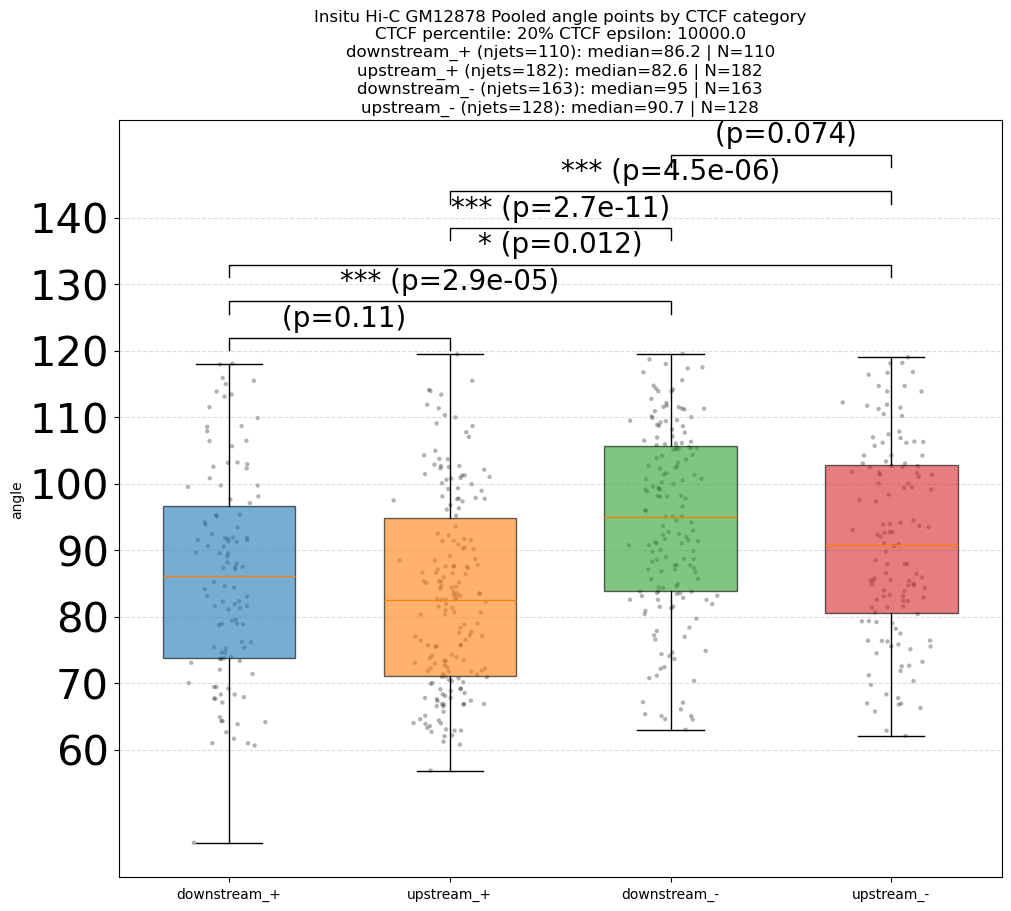

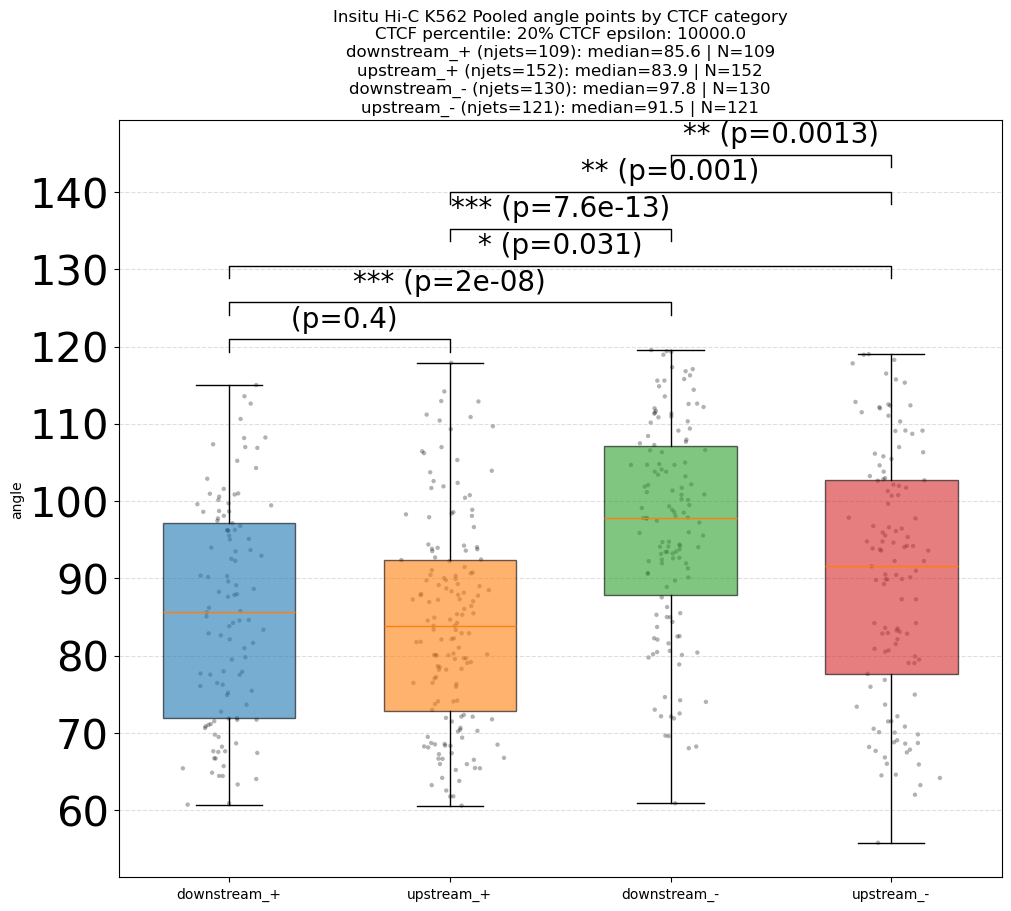

In [7]:
for i, exp in enumerate(exp_list):

    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

    # data per category, in a sensible fixed order (only those actually present)
    order = ['downstream_+', 'upstream_+', 'downstream_-', 'upstream_-']
    categories = [c for c in order if c in exp['category'].unique()]

    # Each point in the boxplot is a jet: take the mean angle of its points
    clean_data = [exp.loc[exp['category'] == c].groupby('unique_id')['angle'].mean().values for c in categories]

    num_jets = [len(exp.loc[exp['category'] == c]['unique_id'].unique()) for c in categories]

    n_cat = len(categories)
    positions_x = np.arange(1, n_cat + 1)

    fig, ax = plt.subplots(1, 1, layout='constrained', figsize=(2 + 2 * n_cat, 9))

    # stat title + pairwise significance
    categories_with_n = [f"{cat} (njets={num})" for cat, num in zip(categories, num_jets)]
    title = title_boxplot(f"{names[i]} Pooled angle points by CTCF category\nCTCF percentile: {perc}% CTCF epsilon: {motif_eps}", categories_with_n, clean_data)

    add_pairwise_sig(ax, positions_x, clean_data, fontsize=20, pad_from_max=-5, y_pad=0.075)

    bp = ax.boxplot(clean_data, patch_artist=True, positions=positions_x, widths=0.6)

    # color each box
    for patch, col in zip(bp['boxes'], colors[:n_cat]):
        patch.set_facecolor(col)
        patch.set_alpha(0.6)

    # jittered scatter on top
    for j, vals in enumerate(clean_data):
        y = np.asarray(vals, dtype=float)
        x = np.full_like(y, positions_x[j]) + np.random.normal(0, 0.08, size=len(y))
        ax.scatter(x, y, alpha=0.3, s=10, color='k', edgecolor='none')

    ax.set_xticks(positions_x)
    ax.set_xticklabels(categories, rotation=0)
    ax.set_ylabel("angle")
    ax.set_title(title)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    ax.set_yticks([60, 70, 80, 90, 100, 110, 120, 130, 140])

    ax.tick_params(axis='y', labelsize=30)

    plt.savefig(f"{save_path}/{data_name}_{names[i]}_boxplot-CTCF-category-filter-perc-{perc}-eps-{motif_eps}_mean-angle.png")

    plt.show()